## Name: Abbas Nadir

## Roll. No: A3 34

## ML Lab

In [16]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay)

pd.set_option('display.max_columns', None)

In [9]:
df = pd.read_csv('glass.csv')

In [10]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [18]:
# Basic dataset overview
print("Dataset shape:", df.shape)

Dataset shape: (213, 10)


In [19]:

print("\nColumn names:")
print(df.columns.tolist())


Column names:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']


In [20]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 213 entries, 0 to 212
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      213 non-null    float64
 1   Na      213 non-null    float64
 2   Mg      213 non-null    float64
 3   Al      213 non-null    float64
 4   Si      213 non-null    float64
 5   K       213 non-null    float64
 6   Ca      213 non-null    float64
 7   Ba      213 non-null    float64
 8   Fe      213 non-null    float64
 9   Type    213 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [12]:
# Check missing values and duplicate rows
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)


Missing values in each column:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Duplicate rows: 1
Shape after removing duplicates: (213, 10)


In [14]:
# Statistical summary
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000
mean,1.518348,13.404085,2.679202,1.449484,72.655070,0.498873,8.954085,0.175869,0.057277,2.788732
std,0.003033,0.816662,1.443691,0.495925,0.773998,0.653185,1.425882,0.498245,0.097589,2.105130
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516520,12.900000,2.090000,1.190000,72.280000,0.130000,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.560000,8.600000,0.000000,0.000000,2.000000
75%,1.519150,13.810000,3.600000,1.630000,73.090000,0.610000,9.150000,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


# Count plot, Bar plot, Pie chart, histogram, Histogram + KDE, box plot, heatmap, scatter plot, pair plot, correlation matrix, IQR

In [15]:
feature_cols = [col for col in df.columns if col != "Type"]

print("Features used for plots:")
print(feature_cols)

Features used for plots:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']


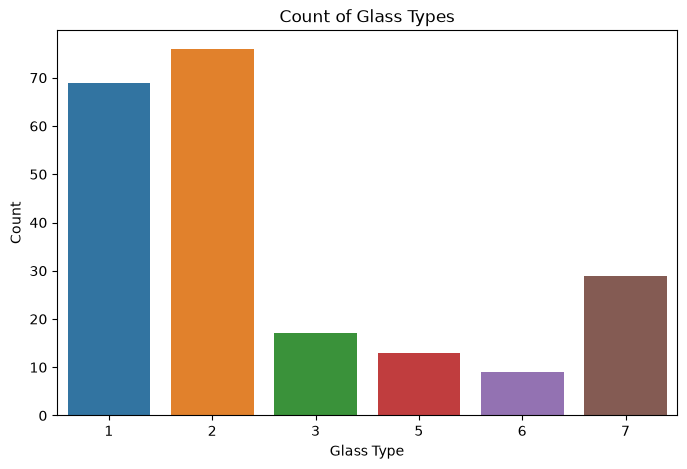

In [16]:
# Count plot

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Type", hue="Type", palette="tab10", legend=False)

plt.title("Count of Glass Types")
plt.xlabel("Glass Type")
plt.ylabel("Count")

plt.show()

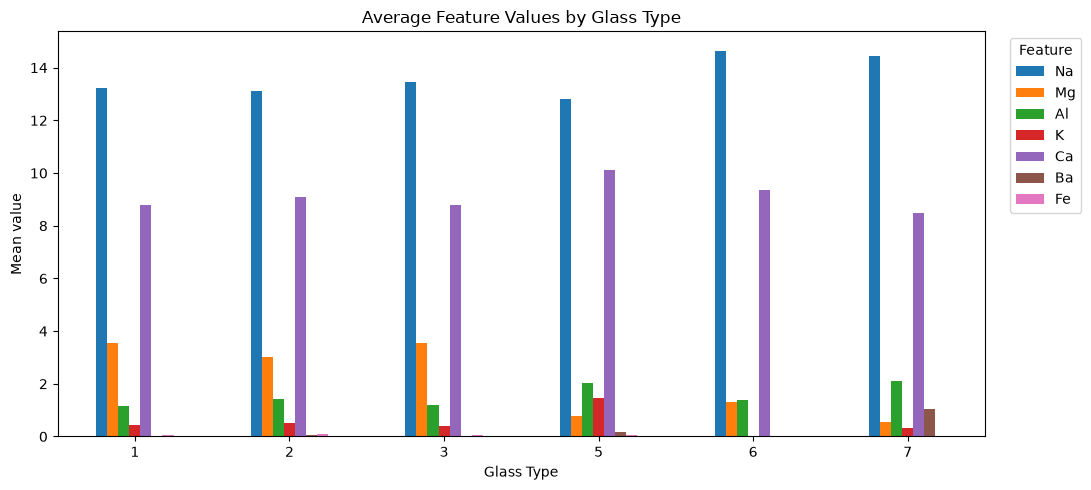

In [17]:
# Bar plot

type_means = df.groupby("Type")[["Na", "Mg", "Al", "K", "Ca", "Ba", "Fe"]].mean()

type_means.plot(kind="bar", figsize=(11, 5))

plt.title("Average Feature Values by Glass Type")
plt.xlabel("Glass Type")
plt.ylabel("Mean value")
plt.xticks(rotation=0)
plt.legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

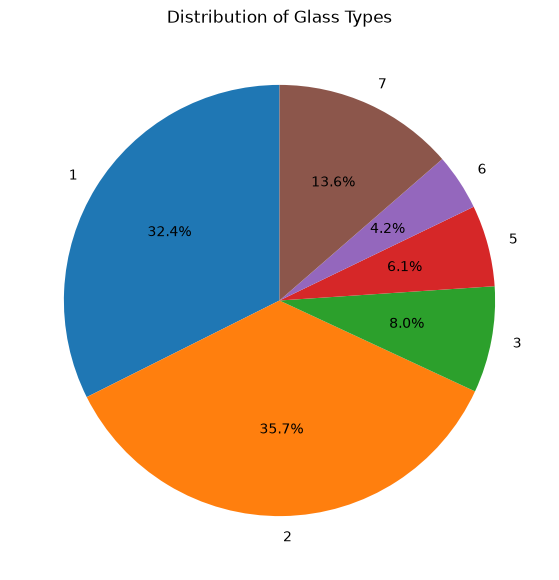

In [18]:
# Pie chart

type_counts = df["Type"].value_counts().sort_index()

plt.figure(figsize=(7, 7))

plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90)

plt.title("Distribution of Glass Types")

plt.show()

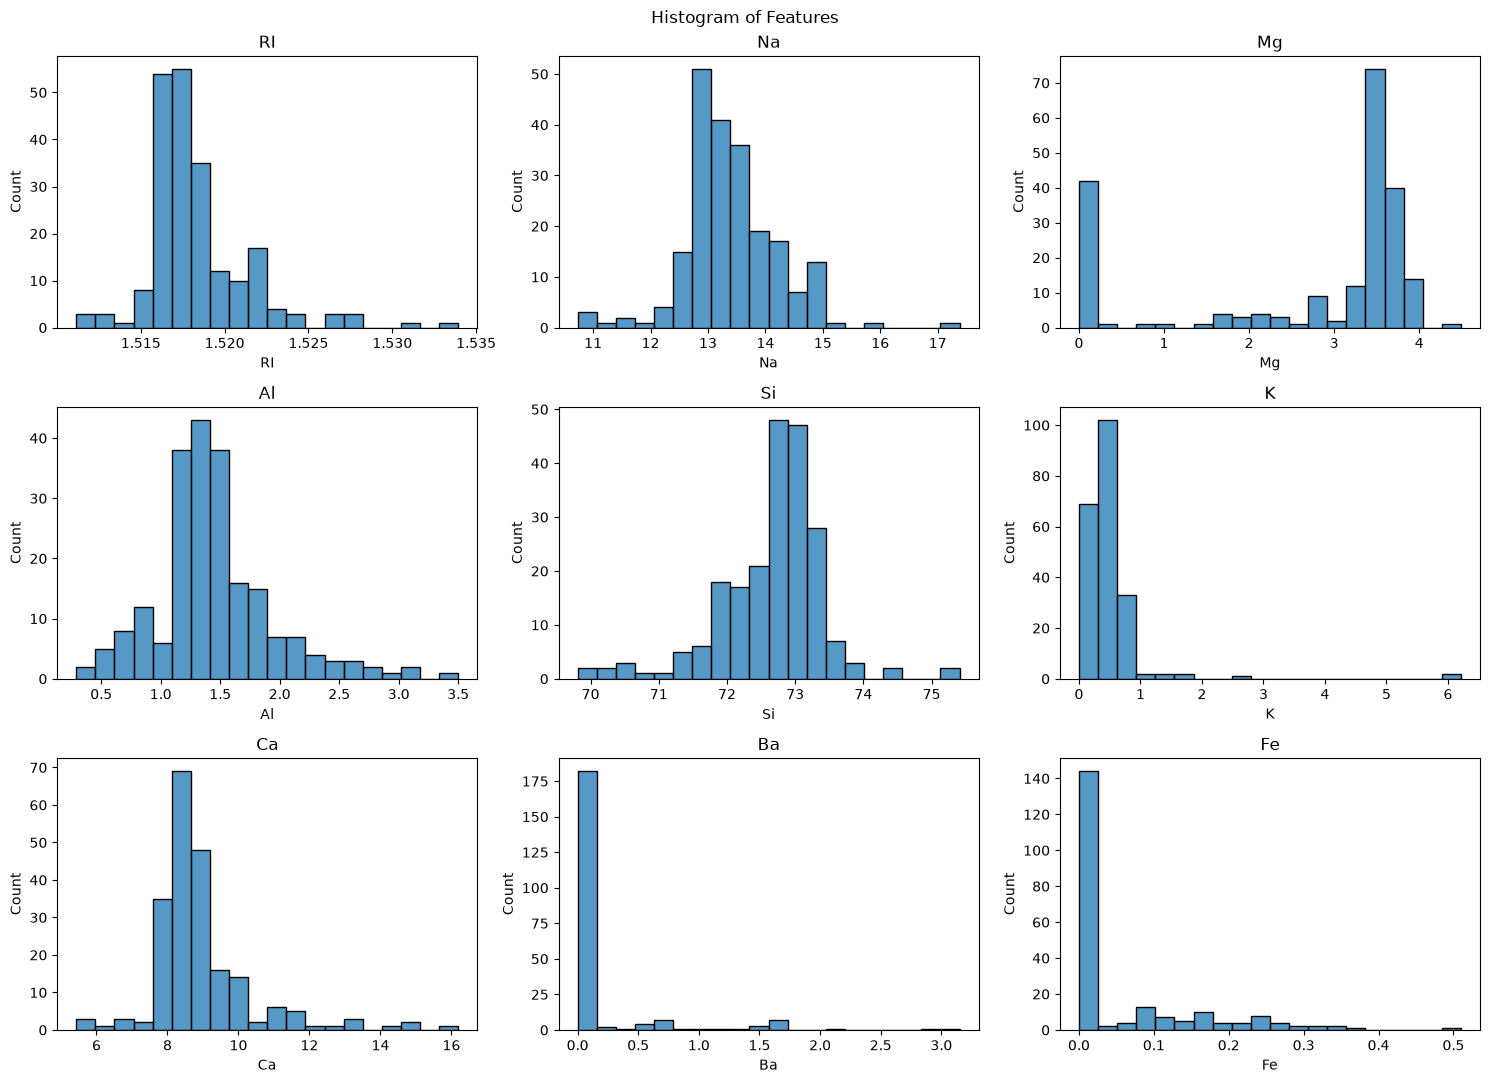

In [19]:
# Histogram

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, col in zip(axes.flatten(), feature_cols):
    sns.histplot(data=df, x=col, bins=20, ax=ax)
    ax.set_title(col)

fig.suptitle("Histogram of Features")

plt.tight_layout()
plt.show()

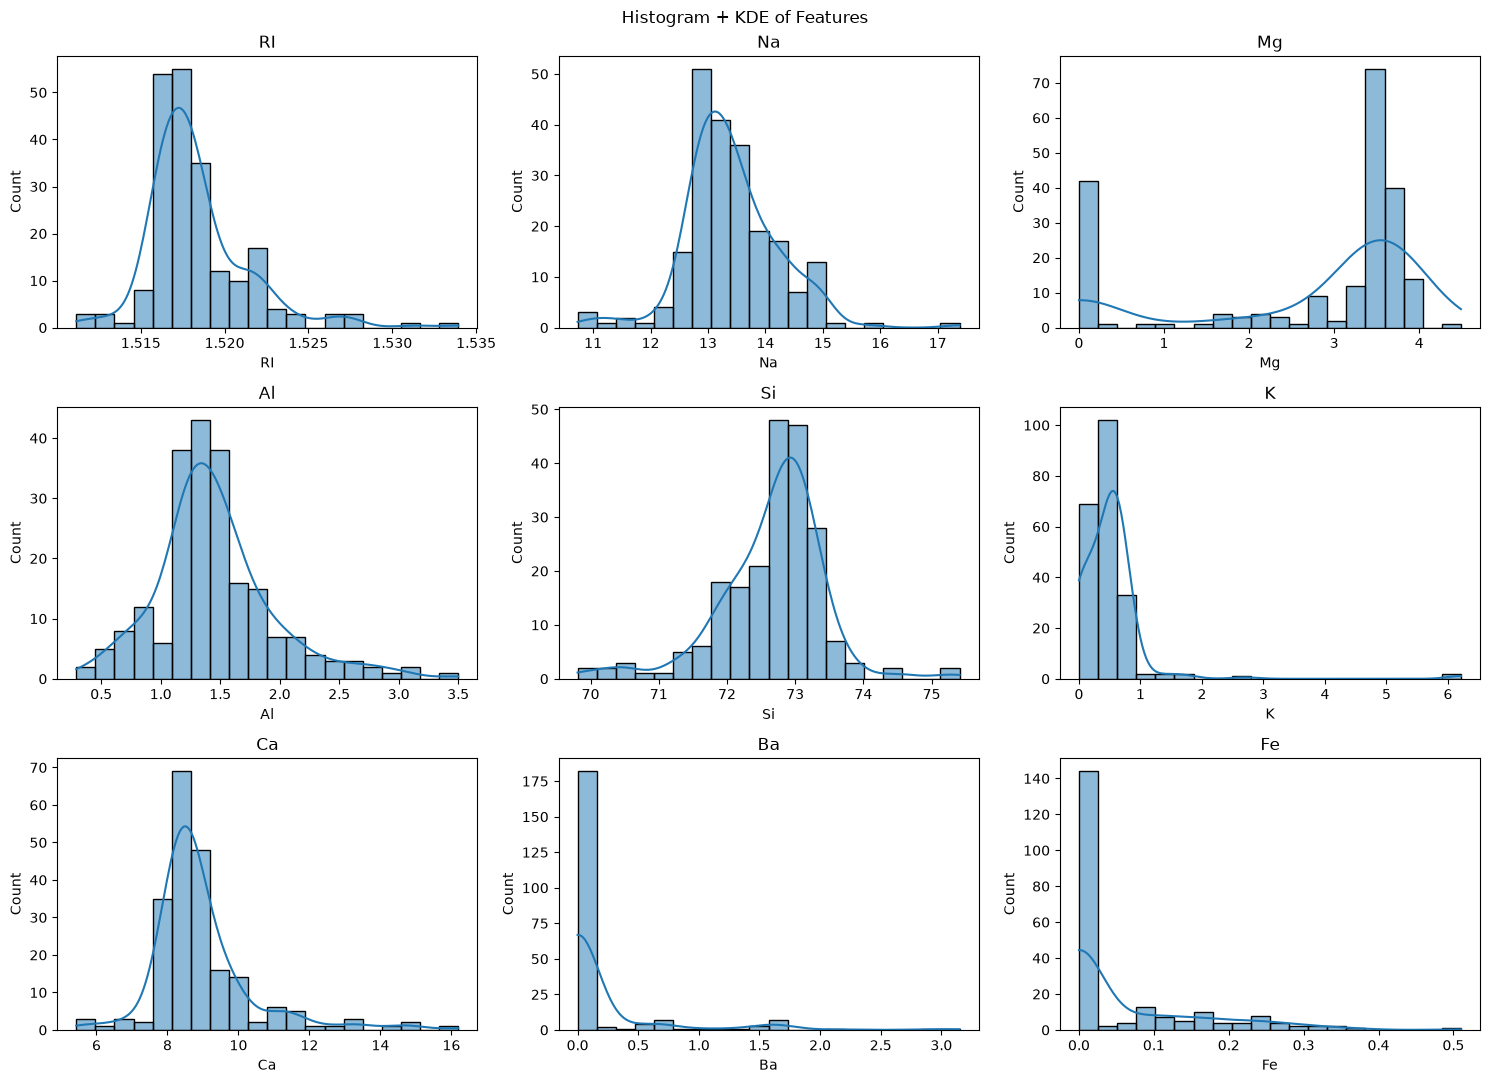

In [20]:
# Histogram + KDE

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, col in zip(axes.flatten(), feature_cols):
    sns.histplot(data=df, x=col, bins=20, kde=True, ax=ax)
    ax.set_title(col)

fig.suptitle("Histogram + KDE of Features")

plt.tight_layout()
plt.show()

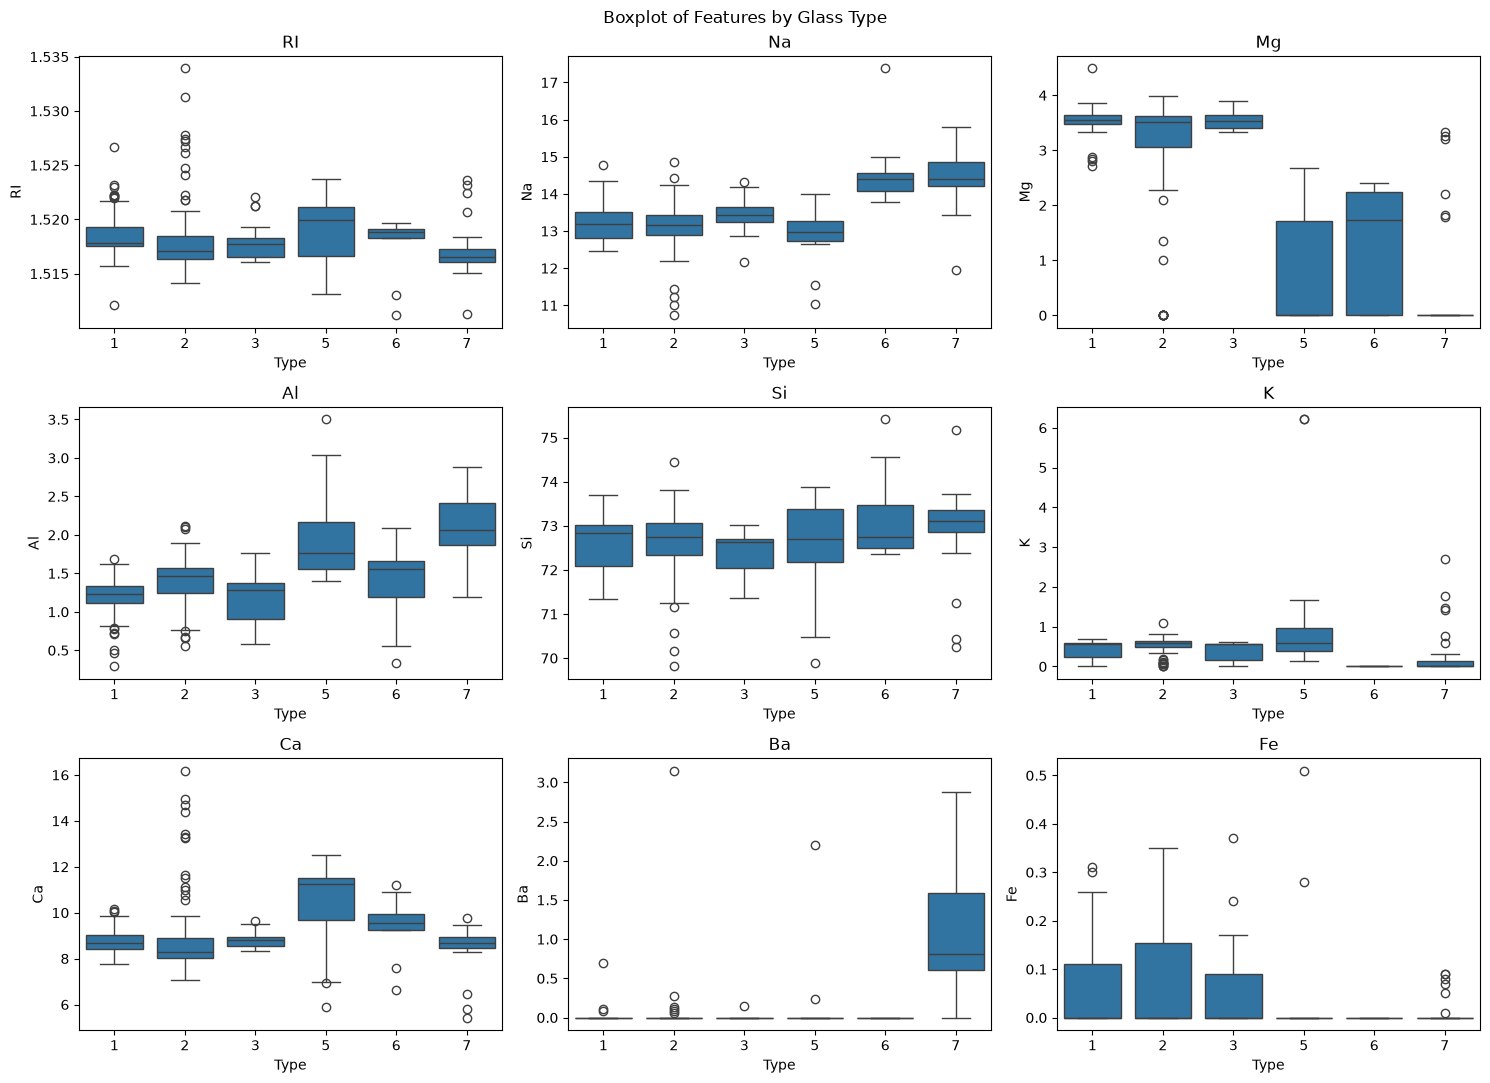

In [21]:
# Box plot

fig, axes = plt.subplots(3, 3, figsize=(15, 11))

for ax, col in zip(axes.flatten(), feature_cols):
    sns.boxplot(data=df, x="Type", y=col, ax=ax)
    ax.set_title(col)

fig.suptitle("Boxplot of Features by Glass Type")

plt.tight_layout()
plt.show()

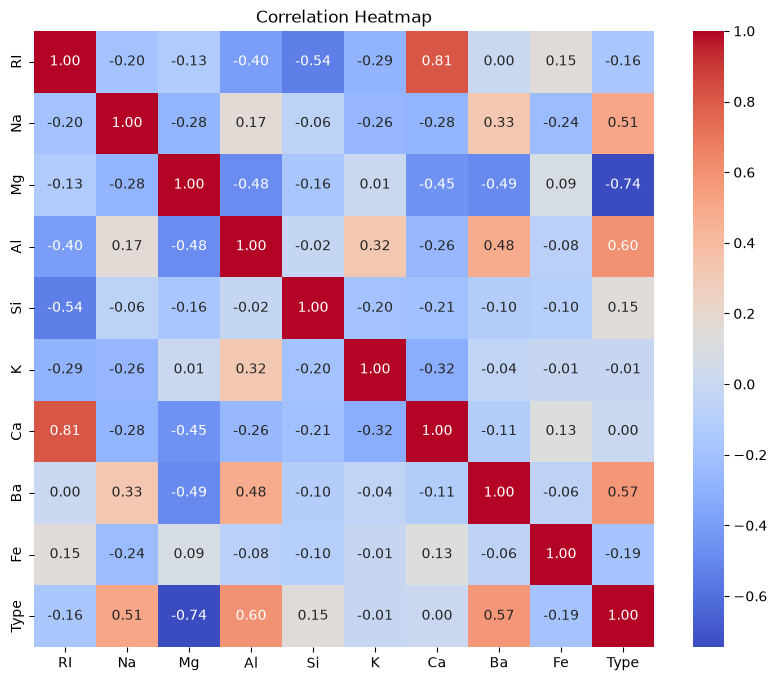

In [22]:
# Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

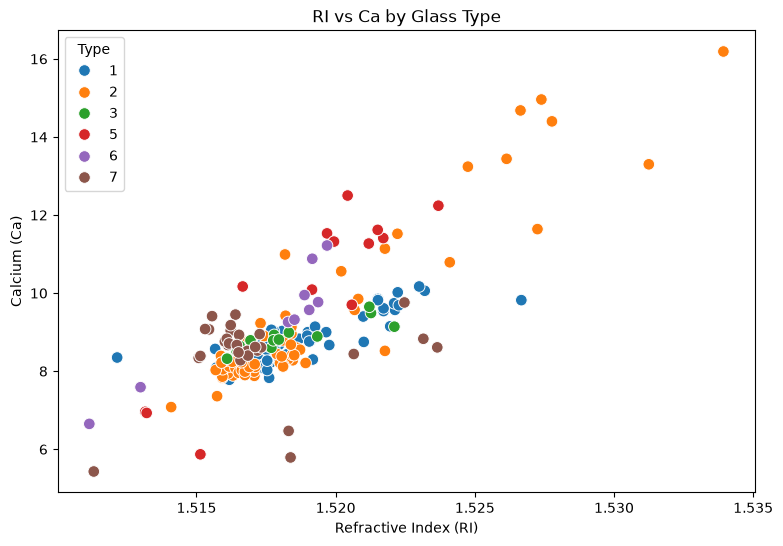

In [23]:
# Scatter plot

plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x="RI", y="Ca", hue="Type", palette="tab10", s=70)

plt.title("RI vs Ca by Glass Type")
plt.xlabel("Refractive Index (RI)")
plt.ylabel("Calcium (Ca)")

plt.show()

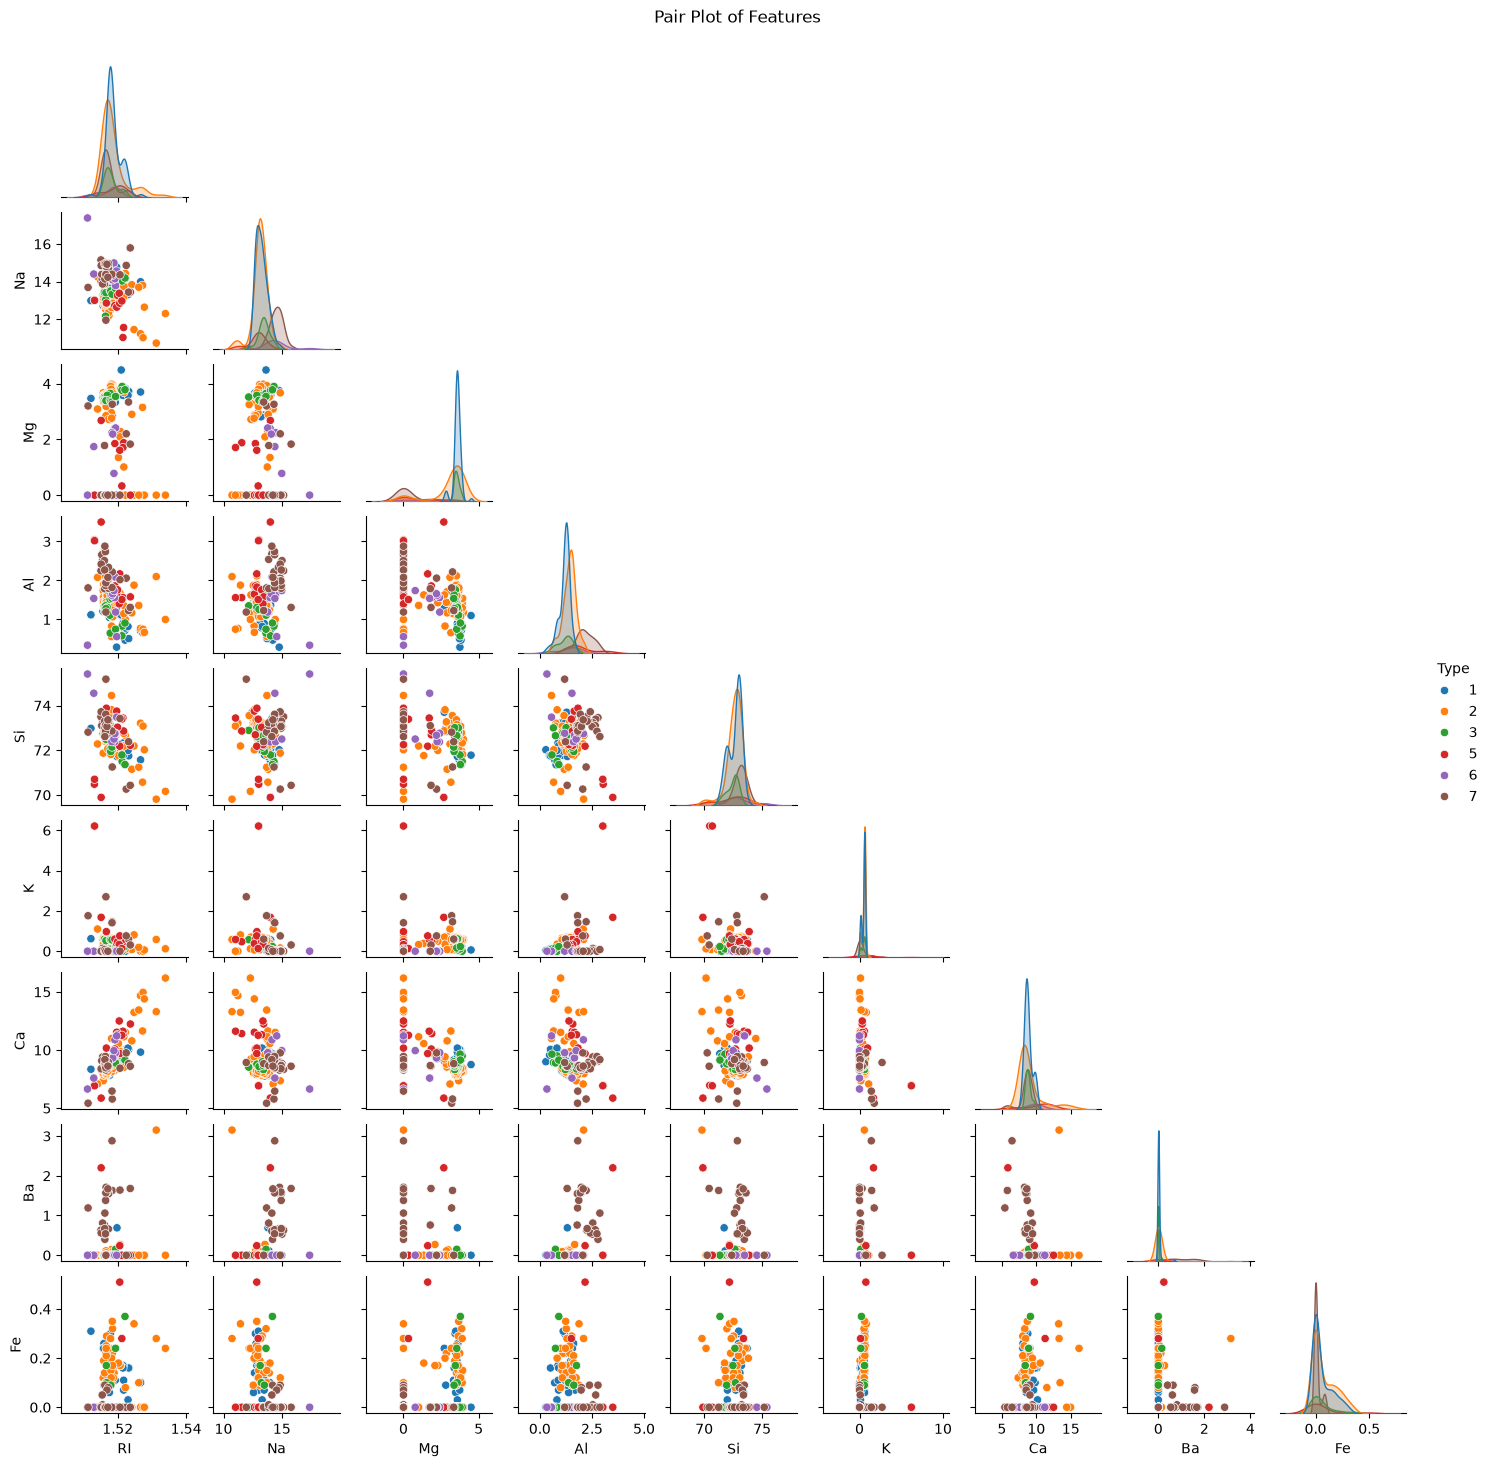

In [24]:
# Pair plot

pair_plot = sns.pairplot(df, hue="Type", palette="tab10", corner=True, height=1.6)

pair_plot.figure.suptitle("Pair Plot of Features", y=1.02)

plt.show()

In [25]:
# Correlation matrix

corr_matrix = df.corr(numeric_only=True).round(2)

corr_matrix

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
RI,1.00,-0.20,-0.13,-0.40,-0.54,-0.29,0.81,0.00,0.15,-0.16
Na,-0.20,1.00,-0.28,0.17,-0.06,-0.26,-0.28,0.33,-0.24,0.51
Mg,-0.13,-0.28,1.00,-0.48,-0.16,0.01,-0.45,-0.49,0.09,-0.74
Al,-0.40,0.17,-0.48,1.00,-0.02,0.32,-0.26,0.48,-0.08,0.60
Si,-0.54,-0.06,-0.16,-0.02,1.00,-0.20,-0.21,-0.10,-0.10,0.15
K,-0.29,-0.26,0.01,0.32,-0.20,1.00,-0.32,-0.04,-0.01,-0.01
Ca,0.81,-0.28,-0.45,-0.26,-0.21,-0.32,1.00,-0.11,0.13,0.00
Ba,0.00,0.33,-0.49,0.48,-0.10,-0.04,-0.11,1.00,-0.06,0.57
Fe,0.15,-0.24,0.09,-0.08,-0.10,-0.01,0.13,-0.06,1.00,-0.19
Type,-0.16,0.51,-0.74,0.60,0.15,-0.01,0.00,0.57,-0.19,1.00


In [26]:
# IQR outlier detection

iqr_rows = []

for col in feature_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    iqr_rows.append([col, q1, q3, iqr, lower_bound, upper_bound, len(outliers)])

iqr_table = pd.DataFrame(
    iqr_rows,
    columns=["Feature", "Q1", "Q3", "IQR", "Lower Bound", "Upper Bound", "Outliers"],
)

iqr_table

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,RI,1.51652,1.51915,0.00263,1.512575,1.523095,17
1,Na,12.90000,13.81000,0.91000,11.535000,15.175000,7
2,Mg,2.09000,3.60000,1.51000,-0.175000,5.865000,0
3,Al,1.19000,1.63000,0.44000,0.530000,2.290000,17
4,Si,72.28000,73.09000,0.81000,71.065000,74.305000,12
5,K,0.13000,0.61000,0.48000,-0.590000,1.330000,7
6,Ca,8.24000,9.15000,0.91000,6.875000,10.515000,27
7,Ba,0.00000,0.00000,0.00000,0.000000,0.000000,38
8,Fe,0.00000,0.10000,0.10000,-0.150000,0.250000,12


In [37]:
label_encoder = LabelEncoder()

df["Class_encoded"] = label_encoder.fit_transform(df["Type"])

print(df[["Type", "Class_encoded"]].head(5))

   Type  Class_encoded
0     1              0
1     1              0
2     1              0
3     1              0
4     1              0


In [38]:
print("Class Mapping:")

for index, class_name in enumerate(label_encoder.classes_):
    print(index, "=", class_name)

Class Mapping:
0 = 1
1 = 2
2 = 3
3 = 5
4 = 6
5 = 7


In [40]:
numerical_features = df.select_dtypes(include=np.number).columns

print("Numerical Features:")
print(numerical_features.tolist())

Numerical Features:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type', 'Class_encoded']


In [41]:
numerical_features = df.select_dtypes(include=np.number).columns

In [54]:
X = df[numerical_features]
X = X.drop(columns=["Type", "Class_encoded"])

In [55]:
X.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0


In [56]:
y = df["Class_encoded"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (213, 9)
y shape: (213,)


In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing sampels:", X_test.shape[0])

Training samples: 170
Testing sampels: 43


In [59]:
GaussianNB()

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [61]:
gnb = GaussianNB()

gnb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](6,)","[55.,61.,14.,10., 7.,23.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](6,)","[0.32,0.36,0.08,0.06,0.04,0.14]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](6,)","[0,1,2,3,4,5]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.001e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['RI','Na','Mg',...,'Ca','Ba','Fe']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](6, 9)","[[ 1.52,13.21, 3.57,..., 8.8 , 0. , 0.06], [ 1.52,13.06, 3.1 ,..., 9.02, 0.06, 0.09], [ 1.52,13.44, 3.55,..., 8.81, 0.01, 0.06], [ 1.52,12.71, 1.01,...,10.09, 0.24, 0.08], [ 1.52,14.76, 1.12,..., 9.61, 0. , 0. ], [ 1.52,14.46, 0.54,..., 8.54, 1.04, 0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](6, 9)","[[0. ,0.21,0.06,...,0.33,0. ,0.01], [0. ,0.37,1.27,...,3.41,0.16,0.01], [0. ,0.29,0.03,...,0.15,0. ,0.01], [0. ,0.66,0.96,...,3.99,0.43,0.03], [0. ,1.28,1.2 ,...,1.89,0. ,0. ], [0. ,0.51,1.15,...,0.66,0.48,0. ]]"


In [62]:
y_pred = gnb.predict(X_test)

print("Predicted labels:")
print(y_pred)

Predicted labels:
[5 1 0 3 0 0 0 1 0 0 0 0 5 4 0 5 5 0 0 1 0 0 5 0 2 0 1 4 1 0 3 0 0 5 0 0 1
 0 1 2 0 4 4]


In [64]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})

print(comparison.head(5))

   Actual  Predicted
0       5          5
1       3          1
2       1          0
3       3          3
4       0          0


In [65]:
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual"])

comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted"])

comparison.head(5)

,Actual,Predicted,Actual_Class,Predicted_Class
0,5,5,7,7
1,3,1,5,2
2,1,0,2,1
3,3,3,5,5
4,0,0,1,1


In [66]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy*100)

Accuracy: 0.5581395348837209
Accuracy (%): 55.81395348837209


In [68]:
precision = precision_score(y_test, y_pred, average='weighted')
print("Precision:", precision)

Precision: 0.5513440048323769


In [70]:
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall:", recall)

Recall: 0.5581395348837209


In [72]:
f1 = f1_score(y_test, y_pred, average='weighted')
print("F1-Score:", f1)

F1-Score: 0.5190979563072586


In [73]:
print("======== MODEL PERFORMANCE ======")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

======== MODEL PERFORMANCE ======
Accuracy  : 0.5581
Precision : 0.5513
Recall    : 0.5581
F1-Score  : 0.5191


In [79]:
print("Classification Report:\n")

print(classification_report(y_test, y_pred, target_names=label_encoder.classes_.astype(str)))

Classification Report:

              precision    recall  f1-score   support

           1       0.55      0.86      0.67        14
           2       0.57      0.27      0.36        15
           3       0.00      0.00      0.00         3
           5       0.50      0.33      0.40         3
           6       0.50      1.00      0.67         2
           7       0.83      0.83      0.83         6

    accuracy                           0.56        43
   macro avg       0.49      0.55      0.49        43
weighted avg       0.55      0.56      0.52        43



In [81]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[12  1  1  0  0  0]
 [ 7  4  1  0  2  1]
 [ 3  0  0  0  0  0]
 [ 0  2  0  1  0  0]
 [ 0  0  0  0  2  0]
 [ 0  0  0  1  0  5]]


In [82]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy :", train_accuracy)
print("Testing Accuracy  :", test_accuracy)

Training Accuracy : 0.5588235294117647
Testing Accuracy  : 0.5581395348837209


In [83]:
GaussianNB(priors=None)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


## Main_Hyperparameters

In [84]:
GaussianNB(var_smoothing = 1e-9)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [85]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [89]:
smoothing_values = [1e-12, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
results=[]

for value in smoothing_values:
    model = GaussianNB(var_smoothing=value)

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    acc = accuracy_score(y_test,prediction)
    prec = precision_score(y_test,prediction, average='weighted')

    rec = recall_score(y_test, prediction, average='weighted')

    f1_value = f1_score(y_test, prediction, average='weighted')

    results.append([value, acc, prec, rec, f1_value])

/home/pro/Fifth Sem/ML/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [91]:
results_df = pd.DataFrame(
    results,
    columns = ["var_smoothing", "Accuracy", "Precision", "Recall", "F1-Score"]
)

results_df

,var_smoothing,Accuracy,Precision,Recall,F1-Score
0,1.000000e-12,0.558140,0.551344,0.558140,0.519098
1,1.000000e-10,0.558140,0.551344,0.558140,0.519098
2,1.000000e-09,0.558140,0.551344,0.558140,0.519098
3,1.000000e-08,0.558140,0.551344,0.558140,0.519098
4,1.000000e-07,0.558140,0.551344,0.558140,0.519098
5,1.000000e-06,0.511628,0.472194,0.511628,0.451498
6,1.000000e-05,0.511628,0.472194,0.511628,0.451498
7,1.000000e-04,0.534884,0.510148,0.534884,0.482835
8,1.000000e-03,0.534884,0.502427,0.534884,0.476969
9,1.000000e-02,0.558140,0.555251,0.558140,0.519151


In [92]:
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>